# Feature correlation & redundancy analysis

Goal: before combining more features (your own, or ones pulled from the QRT_challenge repo), check which candidates carry independent information versus which are redundant with something you already have. This doesn't replace the ablation testing (add-one-at-a-time, compare against fold noise) -- it's a cheap first pass to decide *which* features are worth spending an ablation test on, and to understand *why* some combinations helped (RET_1 + MEDIAN_DAILY_TURNOVER, low correlation) and others didn't (RET_1 * TURNOVER interaction, redundant with what the tree already captures).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

X_train = pd.read_csv('../data/X_train.csv', index_col='ROW_ID')
y_train = pd.read_csv('../data/y_train.csv', index_col='ROW_ID')
total_data = pd.concat([X_train, y_train], axis=1)

## 1. Build your current candidate feature set

Includes the raw base features plus the derived ones you've tested tonight (allocation encoding built leakage-safe here using the FULL training set purely for this correlation analysis -- NOT for modelling, since a model needs the fold-scoped OOF version to avoid leakage. Correlation analysis itself doesn't train anything, so using the full-history version here is fine.)

In [6]:
full_alloc_sign_rate = total_data.groupby('ALLOCATION')['target'].apply(lambda s: (np.sign(s) > 0).mean())
full_alloc_volatility = total_data.groupby('ALLOCATION')['target'].apply(lambda s: s.std())

features_df = pd.DataFrame({
    'RET_1': total_data['RET_1'],
    'RET_4': total_data['RET_4'],
    'MEDIAN_DAILY_TURNOVER': total_data['MEDIAN_DAILY_TURNOVER'],
    'ALLOC_TARGET_ENCODING': total_data['ALLOCATION'].map(full_alloc_sign_rate),
    'ALLOC_VOLATILITY': total_data['ALLOCATION'].map(full_alloc_volatility),
    'RET_1_x_TURNOVER': total_data['RET_1'] * total_data['MEDIAN_DAILY_TURNOVER'],
    'RET_1_RANK_TODAY': total_data.groupby('TS')['RET_1'].rank(pct=True),
})

features_df['target'] = total_data['target']

print(features_df.describe())

               RET_1          RET_4  MEDIAN_DAILY_TURNOVER  \
count  527073.000000  527073.000000           5.234350e+05   
mean        0.000079       0.000034           9.094372e-02   
std         0.003041       0.003051           2.364887e-01   
min        -0.039351      -0.042355           6.917210e-16   
25%        -0.001444      -0.001507           1.892675e-03   
50%         0.000062       0.000035           1.593524e-02   
75%         0.001600       0.001592           4.449061e-02   
max         0.129314       0.131141           1.560090e+00   

       ALLOC_TARGET_ENCODING  ALLOC_VOLATILITY  RET_1_x_TURNOVER  \
count          527073.000000     527073.000000      5.234350e+05   
mean                0.507184          0.002955      2.119942e-05   
std                 0.026753          0.000938      9.354956e-04   
min                 0.384657          0.001070     -3.957437e-02   
25%                 0.494060          0.002281     -1.533930e-05   
50%                 0.505940     

## all feature corrilations



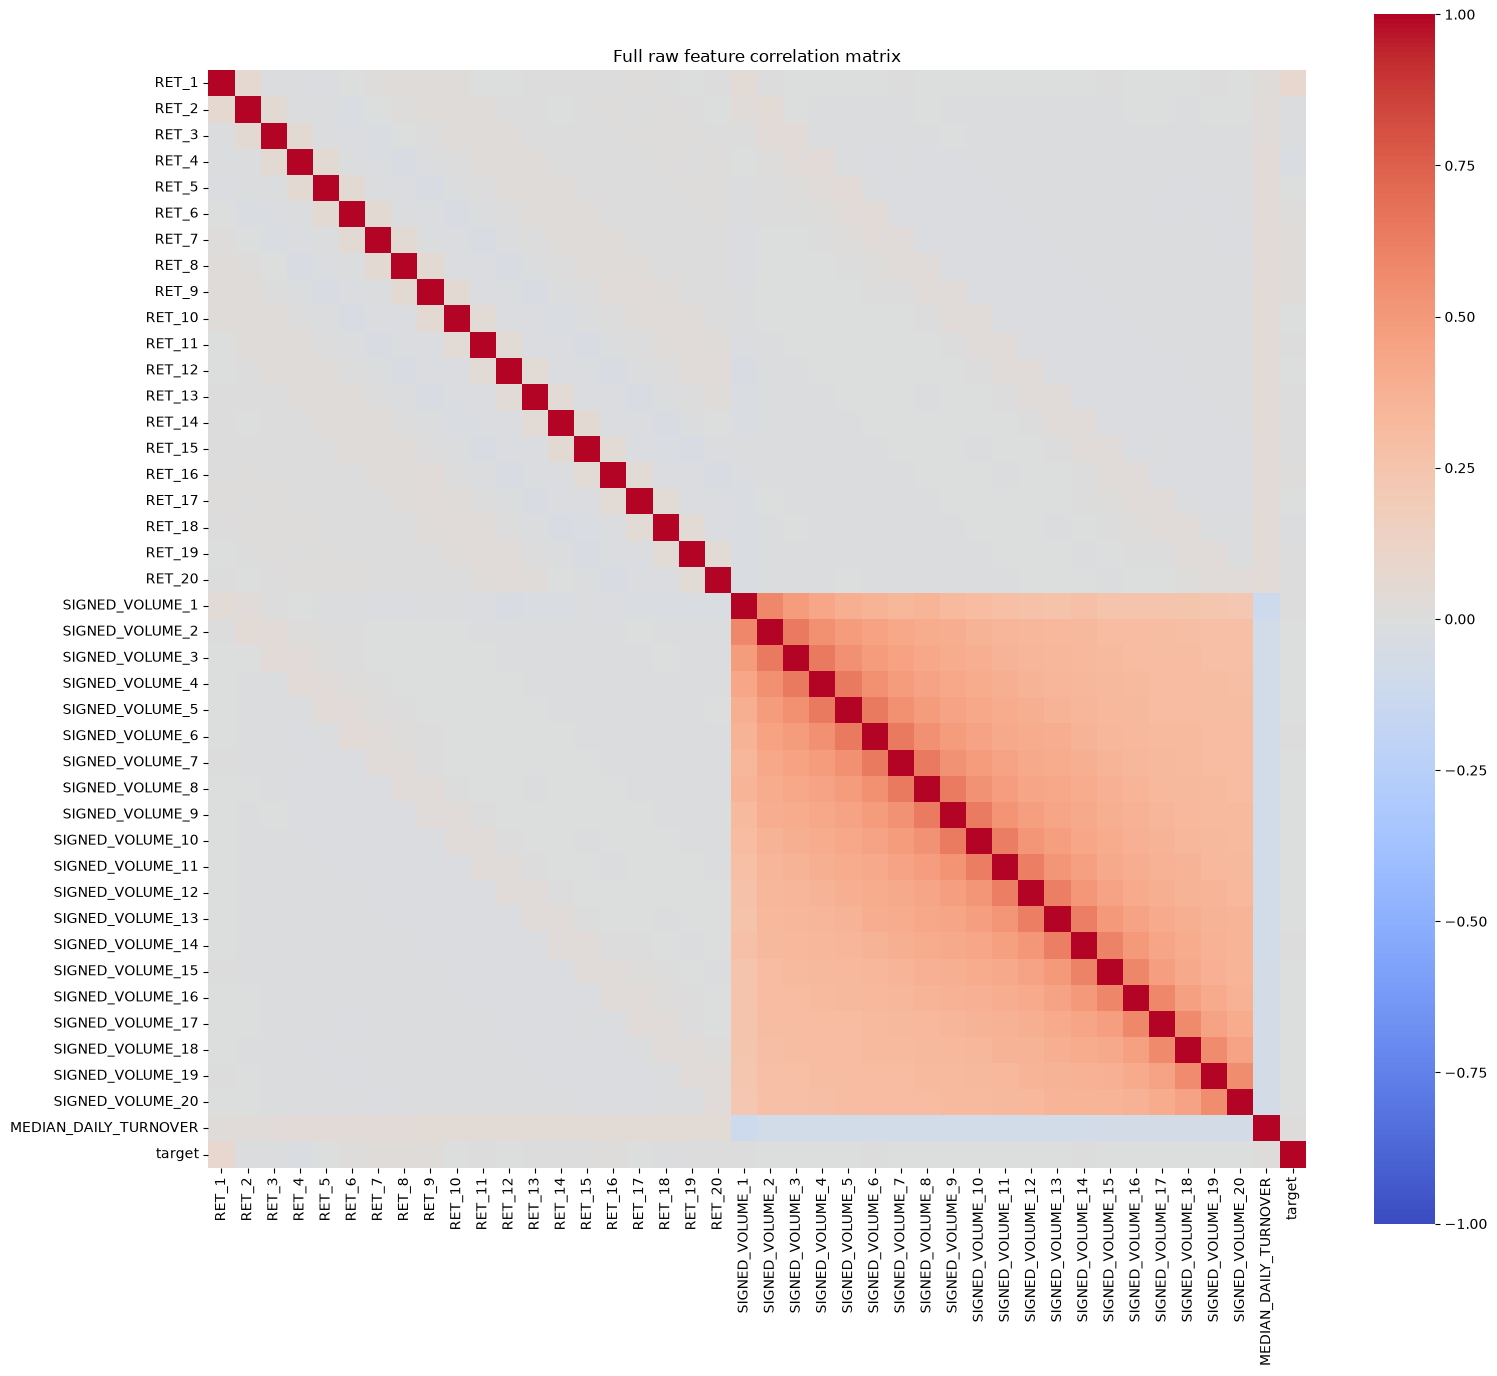

In [7]:
ret_cols = [f'RET_{i}' for i in range(1, 21)]
vol_cols = [f'SIGNED_VOLUME_{i}' for i in range(1, 21)]
all_cols = ret_cols + vol_cols + ['MEDIAN_DAILY_TURNOVER', 'target']

corr_matrix = total_data[all_cols].corr()

plt.figure(figsize=(16, 14))
sns.heatmap(corr_matrix, cmap='coolwarm', center=0, vmin=-1, vmax=1, square=True)
plt.title('Full raw feature correlation matrix')
plt.tight_layout()
plt.show()

## signed volume matrix test


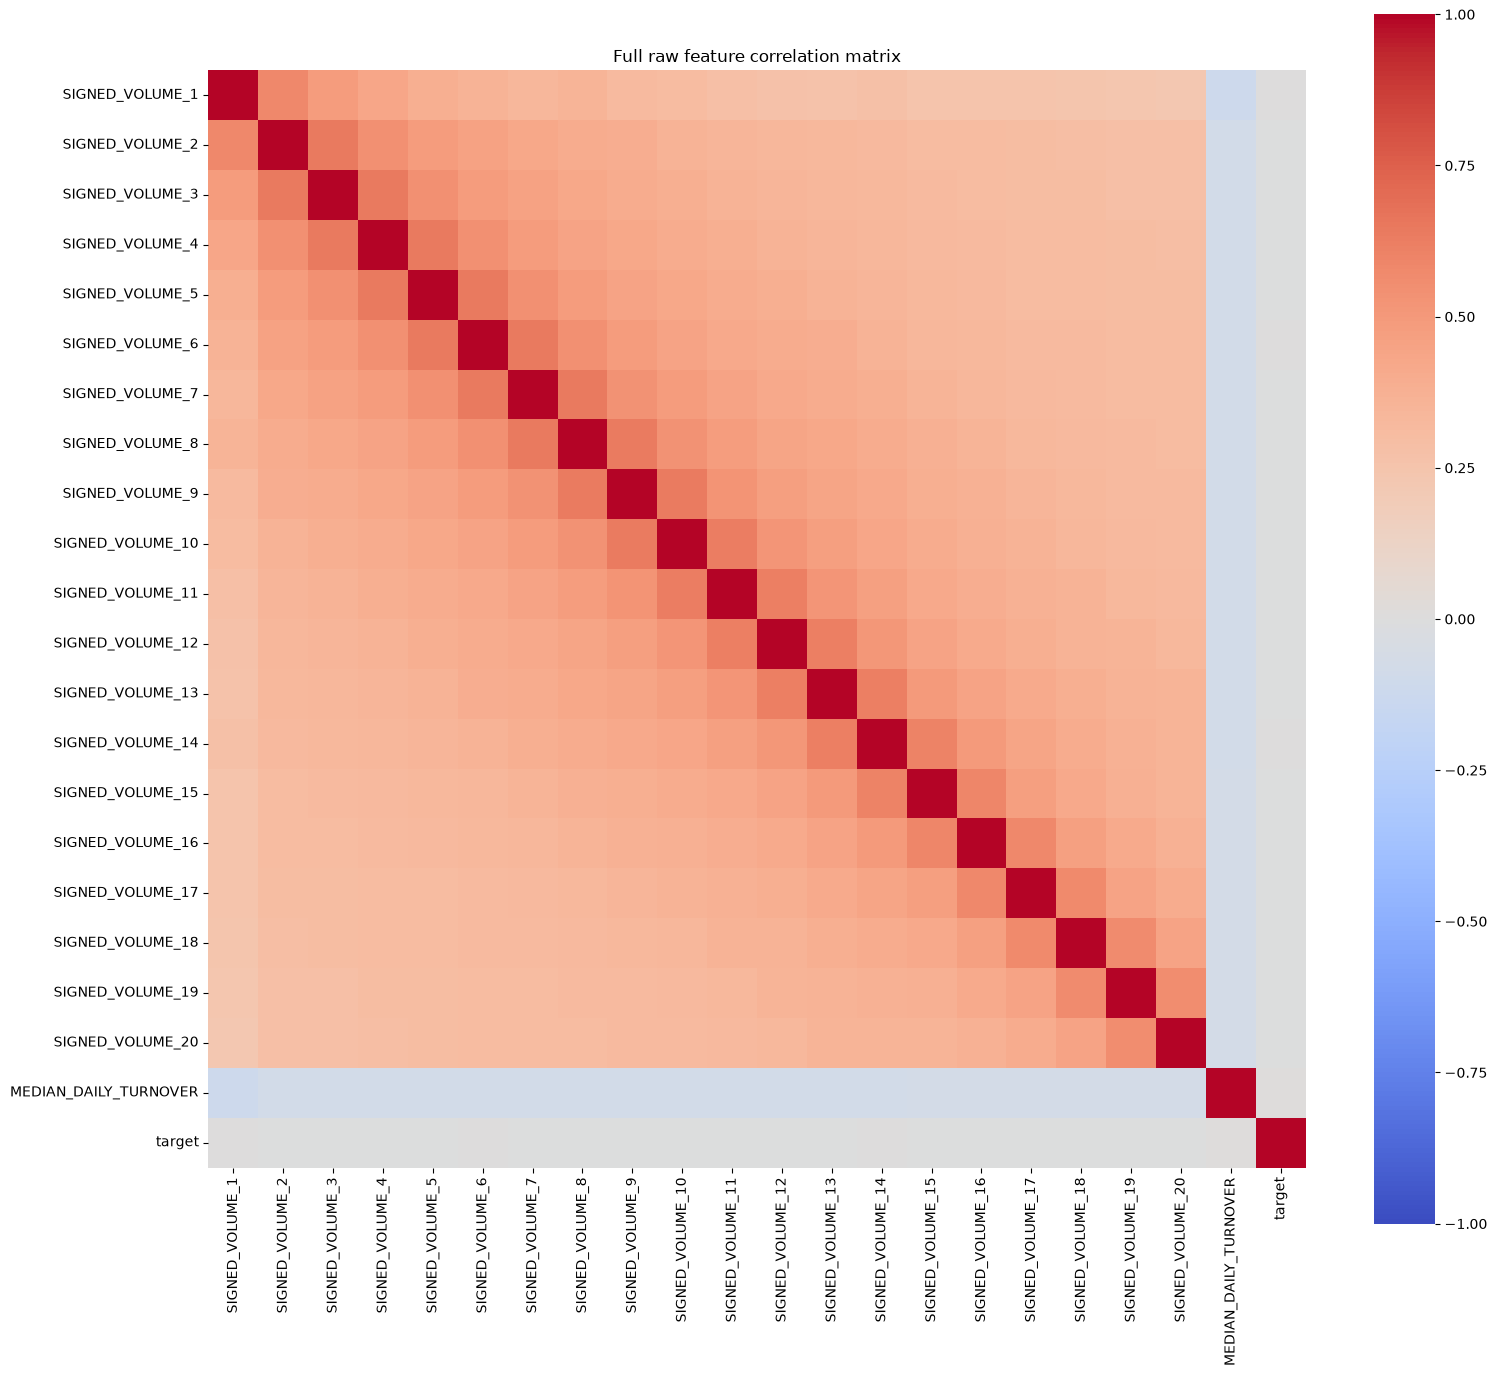

In [9]:

vol_cols = [f'SIGNED_VOLUME_{i}' for i in range(1, 21)]
all_cols =  vol_cols + ['MEDIAN_DAILY_TURNOVER', 'target']

corr_matrix = total_data[all_cols].corr()

plt.figure(figsize=(16, 14))
sns.heatmap(corr_matrix, cmap='coolwarm', center=0, vmin=-1, vmax=1, square=True)
plt.title('Full raw feature correlation matrix')
plt.tight_layout()
plt.show()

In [10]:
print(total_data[vol_cols].corr().values[np.triu_indices(20, k=1)].mean())  # average off-diagonal correlation
print(total_data[vol_cols].corr().values[np.triu_indices(20, k=1)].min())   # weakest pair

0.4017088560622387
0.22962009418444107


In [11]:
from sklearn.decomposition import PCA

vol_data = total_data[vol_cols].fillna(0)  # or a more careful imputation given the NaN patterns you found earlier
pca = PCA(n_components=5)
vol_pcs = pca.fit_transform(vol_data)

print("Explained variance ratio per component:", pca.explained_variance_ratio_)
print("Cumulative:", np.cumsum(pca.explained_variance_ratio_))

Explained variance ratio per component: [0.43707421 0.09539087 0.06558683 0.04804542 0.04006297]
Cumulative: [0.43707421 0.53246508 0.59805191 0.64609733 0.6861603 ]


## 2. Feature-vs-target correlation (which candidates carry signal in isolation)

In [4]:
target_corr = features_df.corr()['target'].drop('target').sort_values(key=abs, ascending=False)
print(target_corr)

RET_1                    0.084853
RET_1_RANK_TODAY         0.060889
ALLOC_TARGET_ENCODING    0.056857
RET_1_x_TURNOVER         0.030123
RET_4                   -0.024339
MEDIAN_DAILY_TURNOVER    0.013405
ALLOC_VOLATILITY        -0.002476
Name: target, dtype: float64


## 3. Feature-vs-feature correlation matrix (redundancy check)

The key question: do any of your candidate features correlate strongly with each other (|corr| > ~0.6-0.7 is a reasonable flag threshold)? If two features are highly correlated AND both correlate with target for the same underlying reason, including both likely adds little -- this is the statistical signature behind why `RET_1_x_TURNOVER` (built directly from two features already in the model) didn't help.

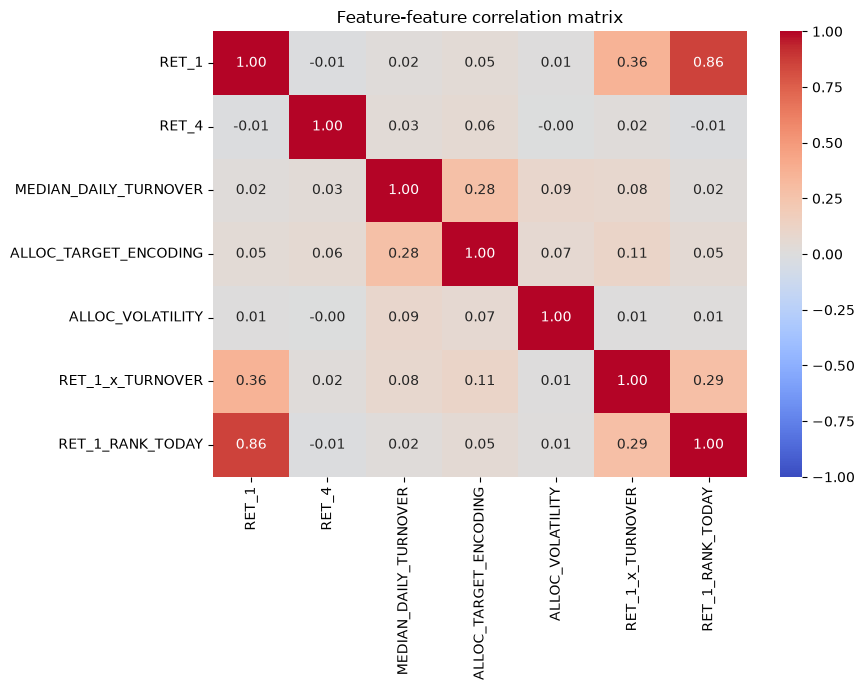

                          RET_1     RET_4  MEDIAN_DAILY_TURNOVER  \
RET_1                  1.000000 -0.012074               0.019739   
RET_4                 -0.012074  1.000000               0.033199   
MEDIAN_DAILY_TURNOVER  0.019739  0.033199               1.000000   
ALLOC_TARGET_ENCODING  0.046690  0.055602               0.275391   
ALLOC_VOLATILITY       0.006625 -0.001170               0.089457   
RET_1_x_TURNOVER       0.362773  0.017615               0.080439   
RET_1_RANK_TODAY       0.855465 -0.008166               0.022774   

                       ALLOC_TARGET_ENCODING  ALLOC_VOLATILITY  \
RET_1                               0.046690          0.006625   
RET_4                               0.055602         -0.001170   
MEDIAN_DAILY_TURNOVER               0.275391          0.089457   
ALLOC_TARGET_ENCODING               1.000000          0.069326   
ALLOC_VOLATILITY                    0.069326          1.000000   
RET_1_x_TURNOVER                    0.114754          0.007

In [5]:
feature_cols = [c for c in features_df.columns if c != 'target']
corr_matrix = features_df[feature_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Feature-feature correlation matrix')
plt.tight_layout()
plt.show()

print(corr_matrix)

## 4. Flag highly-correlated pairs automatically

Useful once you pull in the QRT_challenge repo's ~40 features (BETA_3/10/20, AVG_CORR_UNIV_3/20, MEAN_REV_SIGNAL_5/10, etc.) -- their naming already hints several are the same underlying quantity at different windows, likely highly correlated with each other. This will confirm it quantitatively rather than assuming from the names.

In [ ]:
THRESHOLD = 0.6

pairs = []
for i in range(len(feature_cols)):
    for j in range(i + 1, len(feature_cols)):
        c = corr_matrix.iloc[i, j]
        if abs(c) >= THRESHOLD:
            pairs.append((feature_cols[i], feature_cols[j], c))

pairs_df = pd.DataFrame(pairs, columns=['feature_1', 'feature_2', 'correlation']).sort_values(
    'correlation', key=abs, ascending=False
)
print(f"Pairs with |correlation| >= {THRESHOLD}:")
print(pairs_df)

## 5. Interpretation notes

- A feature with near-zero correlation to target (section 2) isn't automatically useless -- it could still interact usefully with another feature (e.g. MEDIAN_DAILY_TURNOVER had weak standalone correlation but modulated RET_1's reliability). Correlation with target only checks *linear, marginal* signal; it won't catch conditional/interaction effects. Ablation testing (add it to the model, check accuracy) is still the final word -- this notebook narrows down *what's worth ablation-testing*, it doesn't replace that step.
- Two features that are BOTH correlated with target AND highly correlated with each other (section 4) are the ones most likely to be redundant when combined -- worth ablation-testing them together vs separately to confirm before including both.
- Once QRT_challenge's actual feature definitions are available, add their computed columns to the `features_df` block in section 1 and re-run -- this will show directly whether e.g. `BETA_20` and `BETA_10` are near-duplicates (likely), and whether any of their cross-sectional features (`AVG_CORR_UNIV_*`) are independent enough from `ALLOC_TARGET_ENCODING` to be worth combining.